# Aufgabe 12.1 – Clustering univariater Gestenzeitreihen

Offizielle [Aufgabe](https://noxthot.github.io/ws26_industrial_datascience_manuscript/1_act1/8_self_study_session3.html),
[Datenbeschreibung](https://www.timeseriesclassification.com/description.php?Dataset=GesturePebbleZ1),
[aeon k-Means](https://www.aeon-toolkit.org/en/stable/api_reference/auto_generated/aeon.clustering.TimeSeriesKMeans.html),
[KASBA](https://www.aeon-toolkit.org/en/stable/api_reference/auto_generated/aeon.clustering.KASBA.html)
und [MSM](https://www.aeon-toolkit.org/en/stable/api_reference/auto_generated/aeon.distances.msm_distance.html):
gelesen am 26.10.2026. Holder/Bagnall, *Rock the KASBA*,
[2026](https://doi.org/10.1007/s10618-026-01189-9). Datenherkunft/Prüfsummen:
`docs/GESTURE_PEBBLE_SOURCE.md`. KI-Unterstützung: Codex; AWAITING HUMAN REVIEW.

## Ziel und Datenformat
GesturePebbleZ1 enthält pro Fall die z-Achse einer Smartwatch-Geste. Die ursprünglichen
.ts-Dateien enthalten variabel lange Reihen, keine fehlenden Messwerte. TRAIN
(erste Aufnahmesession) und TEST (zweite Session) umfassen dieselben vier Personen;
daher keine Prüfung der Generalisierung auf unbekannte Personen. Keine Zeitpunkte
aus unterschiedlichen Gesten zu einer einzigen langen Reihe verketten.

Ja, eine Formatanpassung ist für die gewählten aeon-Implementierungen erforderlich:
Beide unterstützen keine variablen Längen. Die Liste von (1,L)-Arrays wird durch
lineare Interpolation auf 128 relative Positionen und separate z-Normalisierung
jeder Reihe in ein Array (Fälle, 1 Kanal, 128 Positionen) überführt. Kein Auffüllen
mit Nullen. Die Rohdaten bleiben unverändert. Absolute Dauer, Niveau und Amplitude
gehen bei diesem Vergleich verloren; 128 ist eine Modellwahl, kein Optimum.
Konstante Reihen werden auf null abgebildet; NaN/Inf führen zu einem Fehler.

## Methoden und Vergleich
Euklidisches Zeitreihen-k-Means minimiert die Summe quadrierter Punktabstände zum
arithmetischen Clusterzentrum. KASBA ist ebenfalls ein k-Means-Verfahren, nutzt
hier jedoch die elastische MSM-Metrik, stochastische Subgradienten-Baryzentren,
elastische Initialisierung und metrische Schranken zur Vermeidung von Distanzauswertungen.
Dies unterscheidet sowohl die Geometrie als auch die Optimierung von der Baseline.
Die sechs bekannten Benchmarkklassen begründen k=6, beweisen aber keine natürliche
Clusterzahl. Seed 42, Baseline drei Initialisierungen, beide maximal 30 Iterationen.
KASBA verwendet c=1 sowie seine dokumentierten übrigen Standardparameter.

Nur TRAIN wird gefittet. TEST wird vorhandenen Zentren zugeordnet; keine Anpassung
von Parametern an Testlabels. Klassenlabels dienen ausschließlich nachträglichen
ARI-/NMI-Werten und Kreuztabellen. ARI ist zufallskorrigiert (1: identische Partitionen,
nahe 0: zufallsähnliche Übereinstimmung); NMI misst normierte gemeinsame Information
zwischen Partitionen (0 bis 1). Clusterzahlen sind keine Klassenbezeichnungen.
Inertia unterschiedlicher Distanzfunktionen wird nicht als gemeinsame Güte verglichen.

In [1]:
from pathlib import Path
import sys, os, json
ROOT=Path.cwd()
if not (ROOT/"pyproject.toml").exists(): ROOT=ROOT.parents[1]
sys.path.insert(0,str(ROOT))
os.environ.setdefault("MPLCONFIGDIR",str(ROOT/".tools/matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display
from aeon.distances import msm_distance
from sessions.ch12.clustering import run_experiment, msm_matrix, SOURCE, LENGTH, SEED
OUT=ROOT/"outputs/ch12/exercise_12_1"
OUT.mkdir(parents=True,exist_ok=True)
raw,prepared,models,metrics,assignments=run_experiment()
lengths=pd.DataFrame([{"split":split,"case":i,"length":values.shape[-1]} for split,series in zip(["TRAIN","TEST"],raw) for i,values in enumerate(series)])
display(lengths.groupby("split").length.agg(["count","min","median","max"]))
display(metrics.round(5))
lengths.to_csv(OUT/"lengths.csv",index=False)
metrics.to_csv(OUT/"metrics.csv",index=False)
assignments.to_csv(OUT/"assignments.csv",index=False)
centers=pd.DataFrame([{"method":name,"cluster":k,"position":j,"value":float(value)} for name,model in models.items() for k,center in enumerate(model.cluster_centers_) for j,value in enumerate(center[0])])
centers.to_csv(OUT/"centers.csv",index=False)
summary={"seed":SEED,"target_length":LENGTH,"train":len(raw[0]),"test":len(raw[1]),"missing":sum(int(np.isnan(v).sum()) for split in raw for v in split),"raw_sha256":SOURCE["files"],"metrics":metrics.to_dict(orient="records")}
(OUT/"summary.json").write_text(json.dumps(summary,indent=2)+"\n",encoding="utf-8")
assert prepared[0].shape==(132,1,128) and prepared[1].shape==(172,1,128)
assert summary["missing"]==0

,count,min,median,max
split,,,,
TEST,172,100,185.0,375
TRAIN,132,115,197.5,455


,method,split,n,ARI,NMI,clusters_used,fit_seconds,predict_seconds,n_iter
0,Euclidean k-means,TRAIN,132,0.54514,0.66909,6,0.85570,0.00288,10
1,Euclidean k-means,TEST,172,0.48967,0.59296,6,0.85570,0.00288,10
2,KASBA (MSM),TRAIN,132,0.81532,0.88212,6,1.03938,0.08969,6
3,KASBA (MSM),TEST,172,0.94822,0.95475,6,1.03938,0.08969,6


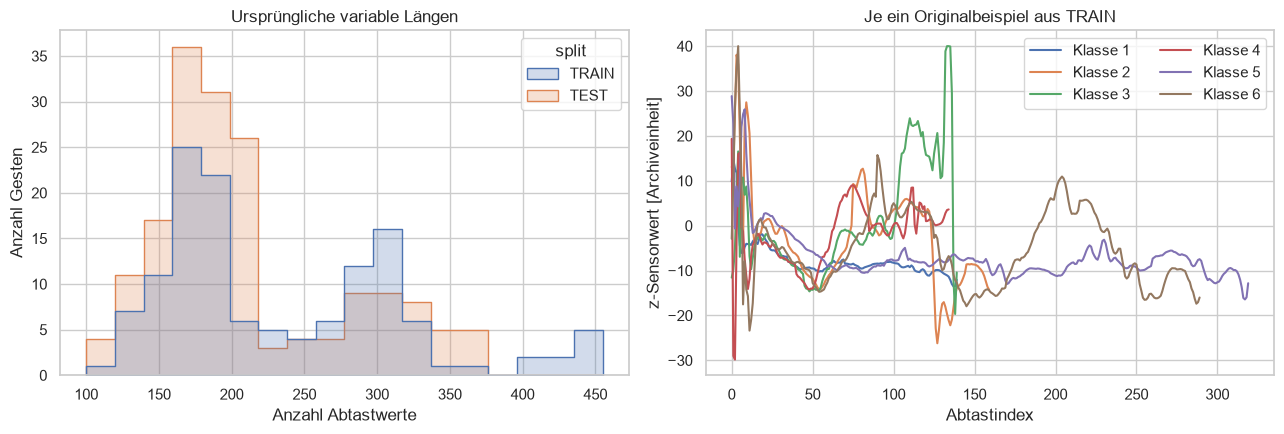

In [2]:
sns.set_theme(style="whitegrid")
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
sns.histplot(data=lengths,x="length",hue="split",element="step",bins=18,ax=axes[0])
axes[0].set(title="Ursprüngliche variable Längen",xlabel="Anzahl Abtastwerte",ylabel="Anzahl Gesten")
train_classes=assignments.query("method == 'Euclidean k-means' and split == 'TRAIN'")["class"].to_numpy()
for label in sorted(set(train_classes)):
    idx=np.flatnonzero(train_classes==label)[0]
    axes[1].plot(raw[0][idx][0],label=f"Klasse {label}")
axes[1].set(title="Je ein Originalbeispiel aus TRAIN",xlabel="Abtastindex",ylabel="z-Sensorwert [Archiveinheit]")
axes[1].legend(ncol=2)
fig.tight_layout();fig.savefig(OUT/"01_data_exploration.png",dpi=150);plt.show()

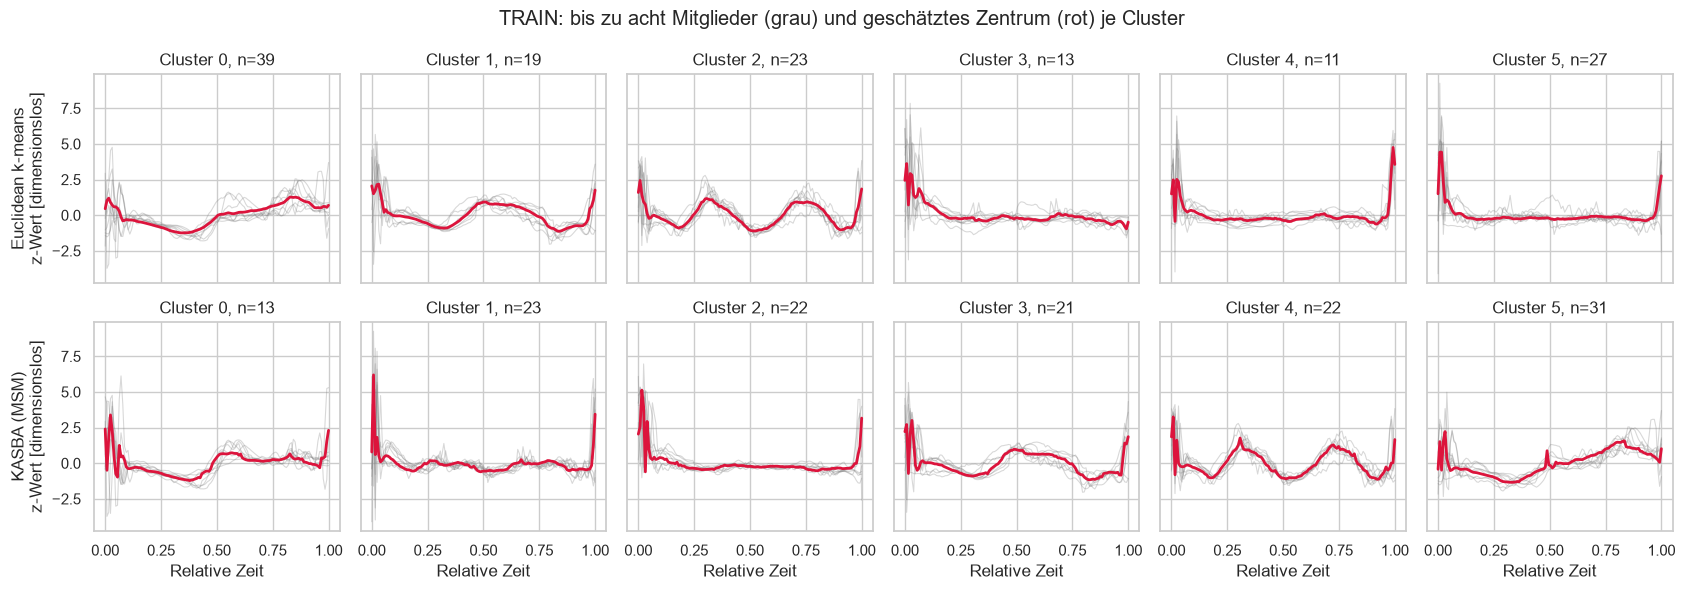

In [3]:
fig,axes=plt.subplots(2,6,figsize=(17,6),sharex=True,sharey=True)
for row,(name,model) in enumerate(models.items()):
    for k in range(6):
        ax=axes[row,k]
        members=prepared[0][model.labels_==k,0,:]
        for member in members[:8]: ax.plot(np.linspace(0,1,LENGTH),member,color="grey",alpha=.3,lw=.8)
        ax.plot(np.linspace(0,1,LENGTH),model.cluster_centers_[k,0],color="crimson",lw=2)
        ax.set_title(f"Cluster {k}, n={len(members)}")
        if row==1: ax.set_xlabel("Relative Zeit")
        if k==0: ax.set_ylabel(name+"\nz-Wert [dimensionslos]")
fig.suptitle("TRAIN: bis zu acht Mitglieder (grau) und geschätztes Zentrum (rot) je Cluster")
fig.tight_layout();fig.savefig(OUT/"02_cluster_centers.png",dpi=150);plt.show()

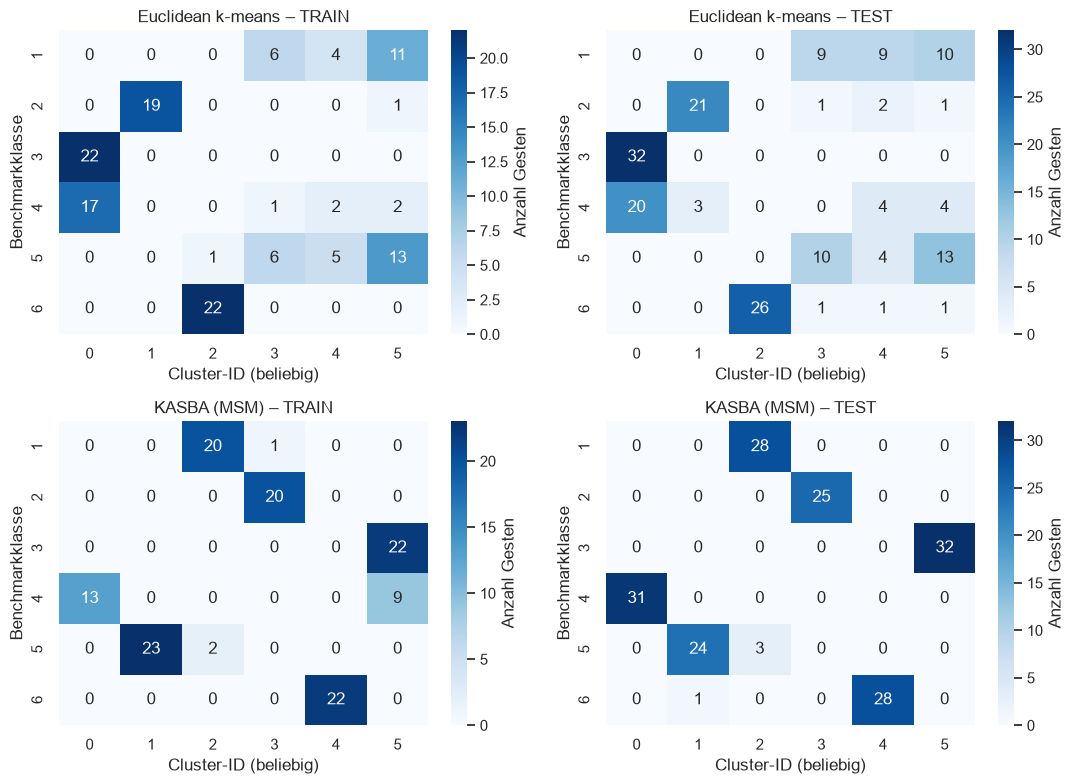

In [4]:
fig,axes=plt.subplots(2,2,figsize=(11,8))
for row,name in enumerate(models):
    for col,split in enumerate(["TRAIN","TEST"]):
        subset=assignments[(assignments.method==name)&(assignments.split==split)]
        counts=pd.crosstab(subset["class"],subset.cluster).reindex(columns=range(6),fill_value=0)
        sns.heatmap(counts,annot=True,fmt="d",cmap="Blues",ax=axes[row,col],cbar_kws={"label":"Anzahl Gesten"})
        axes[row,col].set(title=name+" – "+split,xlabel="Cluster-ID (beliebig)",ylabel="Benchmarkklasse")
        counts.to_csv(OUT/("counts_"+str(row)+"_"+split+".csv"))
fig.tight_layout();fig.savefig(OUT/"03_class_cluster_counts.png",dpi=150);plt.show()

## MSM an einem kleinen Beispiel
Move verändert einen Wert mit Kosten |xᵢ−yⱼ|. Split verdoppelt einen Wert,
Merge fasst benachbarte gleiche Werte zusammen. Die lokale Split-/Merge-Kostenfunktion
C(v,a,b) ist c, wenn v zwischen a und b liegt (einschließlich Grenzen), sonst
c + min(|v−a|, |v−b|). Hier c=1.

D[0,0] = |x₀−y₀|. Die erste Spalte wird durch aufeinanderfolgende
C(xᵢ,xᵢ₋₁,y₀)-Kosten aufgebaut; die erste Zeile analog durch C(yⱼ,x₀,yⱼ₋₁).
Im Inneren gilt:

D[i,j] = min(D[i−1,j−1]+|xᵢ−yⱼ|, D[i−1,j]+C(xᵢ,xᵢ₋₁,yⱼ),
D[i,j−1]+C(yⱼ,xᵢ,yⱼ₋₁)).

MSM(x,y) steht rechts unten. Für x=(1,1,3), y=(1,3) genügt ein Merge der beiden
Einsen: Kosten 1. Umgekehrt benötigt man einen Split mit denselben Kosten.
Eine reine Move-Operation von (1,2) nach (1,3) kostet ebenfalls 1.
Die eigene kleine Matrixrechnung wird gegen aeon geprüft; das Clustering selbst
verwendet die Bibliotheksimplementierung. Die Metrikeigenschaft von MSM erlaubt
KASBA, mittels Dreiecksungleichung unnötige Distanzberechnungen zu vermeiden.

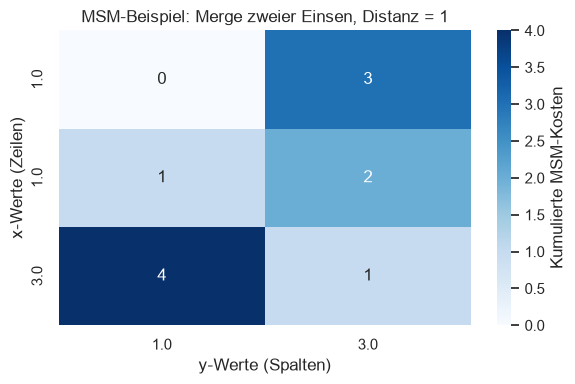

Testvergleich (ARI): {'Euclidean k-means': 0.4896710501680573, 'KASBA (MSM)': 0.948215532685664}
Testvergleich (NMI): {'Euclidean k-means': 0.5929632274540477, 'KASBA (MSM)': 0.9547529260143448}
Übereinstimmung der beiden Testpartitionen (ARI):
0.47660748852269497


In [5]:
x=np.array([1.,1.,3.]);y=np.array([1.,3.])
d=msm_matrix(x,y,c=1.)
np.testing.assert_allclose(d[-1,-1],msm_distance(x,y,c=1.))
assert d[-1,-1]==1. and msm_matrix([1.,2.],[1.,3.])[-1,-1]==1.
pd.DataFrame(d,index=x,columns=y).to_csv(OUT/"msm_example.csv")
fig,ax=plt.subplots(figsize=(6,4))
sns.heatmap(d,annot=True,fmt=".0f",cmap="Blues",xticklabels=y,yticklabels=x,ax=ax,cbar_kws={"label":"Kumulierte MSM-Kosten"})
ax.set(title="MSM-Beispiel: Merge zweier Einsen, Distanz = 1",xlabel="y-Werte (Spalten)",ylabel="x-Werte (Zeilen)")
fig.tight_layout();fig.savefig(OUT/"04_msm_example.png",dpi=150);plt.show()
test_scores=metrics.query("split == 'TEST'").set_index("method")
print("Testvergleich (ARI):",test_scores.ARI.to_dict())
print("Testvergleich (NMI):",test_scores.NMI.to_dict())
print("Übereinstimmung der beiden Testpartitionen (ARI):")
from sklearn.metrics import adjusted_rand_score
parts=[assignments[(assignments.method==name)&(assignments.split=="TEST")].cluster for name in models]
print(adjusted_rand_score(*parts))

## Interpretation und Grenzen
Der berechnete Test-ARI beträgt etwa 0,490 für euklidisches k-Means und 0,948
für KASBA; die Test-NMI liegt bei etwa 0,593 bzw. 0,955. KASBA stimmt in diesem
Lauf stärker mit den Klassen überein. Beide Modelle nutzen alle sechs Cluster
und bleiben mit 10 bzw. 6 Iterationen unter dem Limit von 30. Die Stichprobe und
Vorverarbeitung begrenzen diese Aussage.

Die Tabellen zeigen Clustergrößen, Iterationen, Laufzeiten und die externe
Übereinstimmung mit den Benchmarkklassen separat für TRAIN und TEST. Die
Kreuztabellen zeigen zusätzlich, welche Klassen gemeinsam gruppiert werden.
Ein höherer ARI/NMI bedeutet bessere Übereinstimmung mit diesen Labels unter
dieser Darstellung; es ist keine Klassifikationsgenauigkeit. Die roten Zentren
sind geschätzte Formen, die grauen Linien auf 128 Positionen transformierte
Messungen. Cluster-IDs dürfen zwischen Methoden vertauscht sein.

Zeitliche Verschiebungen werden von euklidischer Distanz punktweise bestraft;
MSM kann sie durch elastische Operationen ausgleichen. Ob dies hier hilft,
muss anhand der tatsächlichen Vergleichszahlen beurteilt werden. Der Vergleich
isoliert nicht die Optimierungsbeschleunigung von KASBA, weil auch die Distanz
und die Initialisierung verschieden sind. Laufzeiten können Numba-JIT-Kompilierung
enthalten und belegen keine allgemeine Geschwindigkeitsrangfolge.

128 Positionen und separate Normalisierung reduzieren Dauer-/Amplitudeninformation;
welche Information für Gesten wichtig ist, bleibt eine fachliche Reviewfrage.
Ein Seed, k=6 und begrenzte Iterationen zeigen keine globale Optimalität oder
Stabilität. Die Testsessions enthalten bekannte Personen, daher begrenzte externe
Generalisation. Keine kausale Interpretation, keine Testlabeloptimierung und keine
Aussage über andere Datensätze. Keine Veröffentlichung/Universitätsabgabe.